# 5. Iterative Computation

Many algorithms involve iterative computation until a solution is found with a desired accuracy.

Also many mathematical models are formulated as a mapping from the current state to the next state, which gives discrete-time dynamics.

References:
* Python Tutorial chapter 4: Control Flow Tools
* Scipy: Optimization and root finding
* Wikipedia: Newton's method, Quasi Newton's method, Logistic map

$$ % Latex macros
\newcommand{\mat}[1]{\begin{pmatrix} #1 \end{pmatrix}}
\newcommand{\p}[2]{\frac{\partial #1}{\partial #2}}
\newcommand{\b}[1]{\boldsymbol{#1}}
\newcommand{\w}{\boldsymbol{w}}
\newcommand{\x}{\boldsymbol{x}}
\newcommand{\y}{\boldsymbol{y}}
$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

## Newton's method
For a linear equation $A x = b$, or $A x - b = 0$, the solution is given using the inverse matrix as

$$x = A^{-1} b. $$  

For a general nonlinear equation $f(x) = 0$, the solution may require iterative approximation.
A typical way is by the Newton's method:  

$$x_{k+1} = x_k - \frac{f(x_k)}{f'(x_k)} $$

starting from an initial guess $x_0$.

### Example
Let us define a plynomial function and its derivative.

In [2]:
def poly(x, a):
    """Polynomial a[0] + a[1]*x + ... + a[n]*x**n"""
    n = len(a)  # order+1
    xp = np.array([x**i for i in range(n)])  # 1, x,.. x**(n-1)
    y = a @ xp
    return y

In [3]:
def d_poly(x, a):
    """Derivative of polynomial a[1] + 2*a[2]*x + ... + n*a[n]*x**(n-1)"""
    b = np.arange(len(a))*a
    return poly(x, b[1:])

In [4]:
a = np.array([3,2,1])

In [5]:
poly(1, a)

np.int64(6)

In [6]:
d_poly(1., a)

np.float64(4.0)

Here is an example polynomial with three zero-crossing points.

a = [ 6 -5 -2  1]


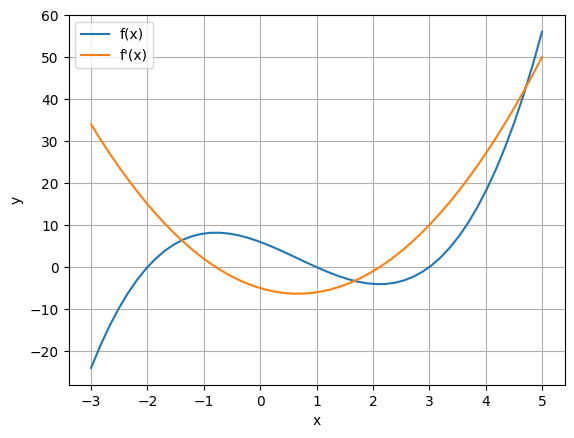

In [7]:
# f(x) = (x-3)(x-1)(x+2) = 6 - 5x -2x^2 + x^3
a = np.array([6, -5, -2, 1])
print('a =', a)
x = np.linspace(-3, 5, 50)
plt.plot(x, poly(x,a), x, d_poly(x,a))
plt.grid('on'); plt.xlabel('x'); plt.ylabel('y');
plt.legend(('f(x)','f\'(x)'));

Here's a simple implementation of Newton's method with visualization.

In [8]:
def newton(f, df, x0, a, target=1e-6, maxstep=20):
    """Newton's method.
        f, df: function and its derivative
        x: initial guess
        a: parameter for f(x,a)
        target: accuracy target"""
    x = np.zeros(maxstep+1)
    y = np.zeros(maxstep)
    x[0] = x0
    for i in range(maxstep):
        y[i] = f(x[i],a)
        if abs(y[i]) < target:
            break  # converged!
        x[i+1] = x[i] - y[i]/df(x[i],a)    # new x
    else:
        print('did not coverge in', maxstep, 'steps.')
    return x[:i+1], y[:i+1]

Let us see how it works.

In [9]:
newton(poly, d_poly, 5, a)

(array([5.        , 3.88      , 3.27527854, 3.04063338, 3.00110572,
        3.00000085, 3.        ]),
 array([5.60000000e+01, 1.49022720e+01, 3.30409339e+00, 4.17958407e-01,
        1.10657543e-02, 8.54778237e-06, 5.11590770e-12]))

In [10]:
newton(poly, d_poly, 0, a)

(array([0.        , 1.2       , 0.98978102, 0.99998301, 1.        ]),
 array([ 6.00000000e+00, -1.15200000e+00,  6.14172290e-02,  1.01951561e-04,
         2.88712054e-10]))

Here is a graphical representation.

In [11]:
def zigsawplot(x, y):
    """zigsaw lines of updates
    (x0,0),(x0,y0),(x1,0), (x1,y1),...(xn,0),(xn,yn)"""
    x = np.repeat(x, 2)  # duplicate items
    y = np.c_[np.zeros_like(y),y].ravel()  # insert zeros
    plt.plot(x, y)

x = 3.0000000000005116  y = 5.115907697472721e-12


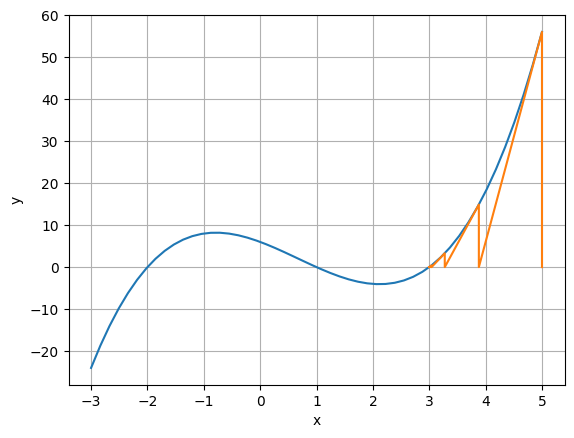

In [12]:
xt, yt = newton(poly, d_poly, 5, a)
print('x =', xt[-1], ' y =', yt[-1])
plt.plot(x, poly(x,a))
zigsawplot(xt, yt)
plt.grid('on'); plt.xlabel('x'); plt.ylabel('y');

Try starting from other initial guesses

x = -2.00000000000004  y = -6.004086117172847e-13


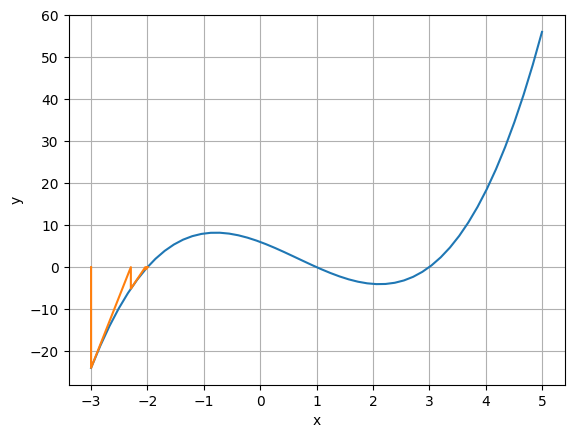

In [13]:
xt, yt = newton(poly, d_poly, -3, a)
print('x =', xt[-1], ' y =', yt[-1])
plt.plot(x, poly(x,a))
zigsawplot(xt, yt)
plt.grid('on'); plt.xlabel('x'); plt.ylabel('y');

x = 0.9999999999963238  y = 2.205702287483291e-11


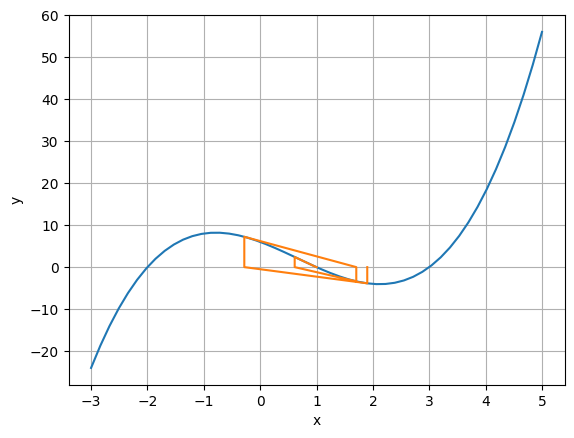

In [14]:
xt, yt = newton(poly, d_poly, 1.9, a)
print('x =', xt[-1], ' y =', yt[-1])
plt.plot(x, poly(x,a))
zigsawplot(xt, yt)
plt.grid('on'); plt.xlabel('x'); plt.ylabel('y');

x = -2.000000000000004  y = -5.861977570020827e-14


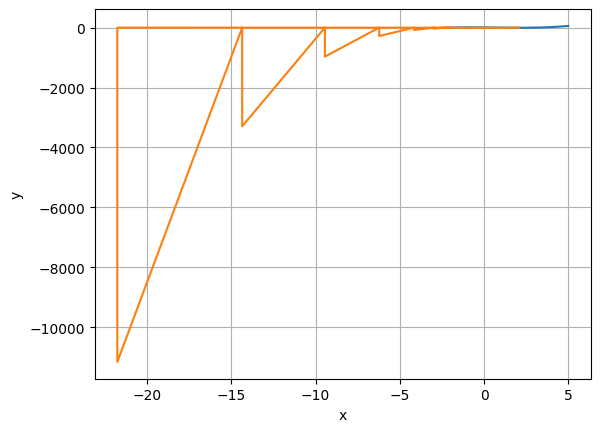

In [15]:
xt, yt = newton(poly, d_poly, 2.1, a)
print('x =', xt[-1], ' y =', yt[-1])
plt.plot(x, poly(x,a))
zigsawplot(xt, yt)
plt.grid('on'); plt.xlabel('x'); plt.ylabel('y');

## Quasi-Newton Method
The derivative $f'(x)$ may not be available or hard to compute.
In that case, we can use the slope between two points to approximate the derivative.

$$f'(x) \simeq \frac{f(x_k)-f(x_{k-1})}{x_k-x_{k-1}} $$

Quasi-Neuton method uses pairs of points to find the solution:

$$x_{k+1} = x_k - f(x_k)\frac{x_k-x_{k-1}}{f(x_k)-f(x_{k-1})} $$

starting from an initial guess $x_0$.

In [16]:
def qnewton(f, x0, x1, a, target=1e-6, maxstep=20):
    """Quasi-Newton's method.
        f: return f
        x: initial guess
        x0, x1: initial guess at two points
        *args: parameter for f(x,*args)
        target: accuracy target"""
    x = np.zeros(maxstep+2)
    y = np.zeros(maxstep+1)
    x[0], x[1] = x0, x1
    y[0] = f(x[0], a)
    for i in range(1, maxstep+1):
        y[i] = f(x[i], a)
        if abs(y[i]) < target:
            break  # converged!
        x[i+1] = x[i] - y[i]*(x[i]-x[i-1])/(y[i] - y[i-1])    # new x
    else:
        print('did not coverge in', maxstep, 'steps.')
    return x[:i+1], y[:i+1]

In [17]:
qnewton(poly, 5, 4, a)

(array([5.        , 4.        , 3.52631579, 3.19955654, 3.05234137,
        3.00641035, 3.00022742, 3.00000102, 3.        ]),
 array([5.60000000e+01, 1.80000000e+01, 7.34800991e+00, 2.28227200e+00,
        5.42734403e-01, 6.43913708e-02, 2.27452245e-03, 1.01671083e-05,
        1.61831082e-09]))

In [18]:
def qnplot(x, y):
    """lines for quasi-Newton updates
    (x0,0),(x0,y0),(x2,0), (x1,0),(x1,y1),(x3,0),...(xn,0),(xn,yn)"""
    for i in range(len(x)-2):
        plt.plot([x[i],x[i],x[i+2]], [0,y[i],0])

x = 3.000000000161831  y = 1.6183108186851314e-09


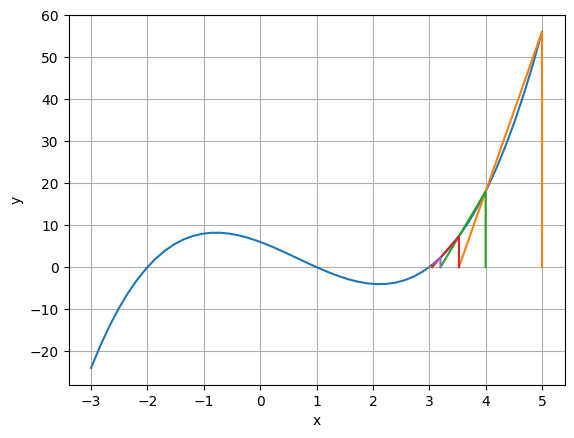

In [19]:
xt, yt = qnewton(poly, 5, 4, a)
print('x =', xt[-1], ' y =', yt[-1])
plt.plot(x, poly(x,a))
qnplot(xt, yt)
plt.grid('on'); plt.xlabel('x'); plt.ylabel('y');

x = 0.999999939072668  y = 3.655639956301471e-07


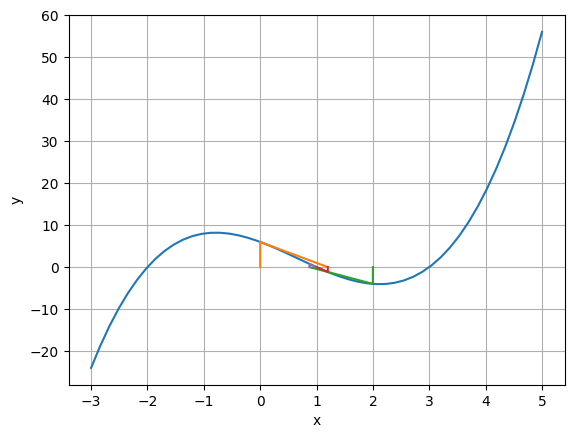

In [20]:
xt, yt = qnewton(poly, 0, 2, a)
print('x =', xt[-1], ' y =', yt[-1])
plt.plot(x, poly(x,a))
qnplot(xt, yt)
plt.grid('on'); plt.xlabel('x'); plt.ylabel('y');

x = -2.0000000573764902  y = -8.60647380918067e-07


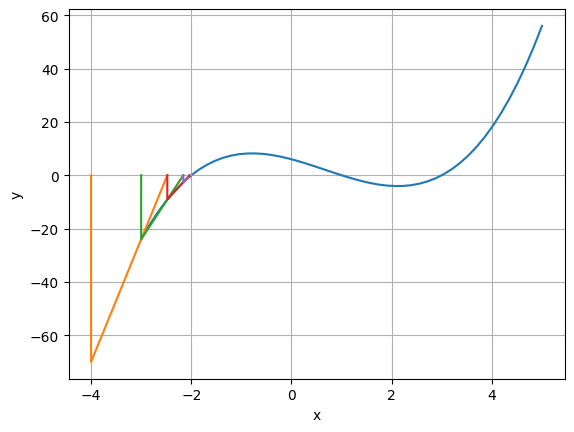

In [21]:
xt, yt = qnewton(poly, -4, -3, a)
print('x =', xt[-1], ' y =', yt[-1])
plt.plot(x, poly(x,a))
qnplot(xt, yt)
plt.grid('on'); plt.xlabel('x'); plt.ylabel('y');

Define your own function and see how Newton's or Quasi-Newton method works.

## Newton's method in n dimension
Newton's method can be generalized for $n$ dimensional vector $\b{x} \in \mathbb R^n$ and $n$ dimensional function $\b{f}(\b{x})\in \mathbb R^n$ to find the solution $\b{f}(\b{x})=\b{0}$ as

$$ \b{x}_{k+1} = \b{x}_k - J(\b{x}_k)^{-1}\b{f}(\b{x}_k) $$

where $J(\b{x})$ is the *Jacobian matrix*

$$ J(\b{x}) = \mat{\p{f_1}{x_1} & \cdots & \p{f_1}{x_n}\\
    \vdots & & \vdots\\
    \p{f_n}{x_1} & \cdots & \p{f_n}{x_n}} $$

In [22]:
def mpoly(x, A):
    """multiple n dim p order polynomials
    a0 + a1*x1 +...+ an*xn + a_n+1*x1**2 +...+ a_2n*xn**2 + ... +a_pn*xn**p
    x: n or n*k
    A: m*(n*p+1)
    """
    n = len(x)   # input dimension
    p = (A.shape[1]-1)//n  # polynomial order
    xp = np.concatenate([x**i for i in range(p+1)])  # x**0=1
    #print(xp)
    return A @ xp[n-1:]  # only one 1

In [23]:
def dmpoly(x, A):
    """ Jacobian of multiple n dim p order plynomials
    a0 + a1*x1 +...+ an*xn + a_n+1*x1**2 +...+ a_2n*xn**2 + ... +a_pn*xn**p
    x: n or n*k
    A: m*(n*p+1)
    J = [[a[1] + 2*a[3]*x[0]+ a[5]*x[1], a[2] + 2*a[4]*x[1] + a[5]*x[0]]
    """
    n = len(x)   # input dim
    m = A.shape[0]   # output dim
    p = (A.shape[1]-1)//n  # polynomial order
    Jc = np.zeros((n,m))  # one column of Jacobian
    for i in range(n):  #differentiate by xi: ai + 2*a_n+i +...+p*a_(p-1)n+i
        Ai = np.array([j*A[:,(j-1)*n+i+1] for j in range(1,p+1)]).T
        Jc[i] = mpoly(np.array([x[i]]), Ai)  # for input dimemsion i
        #print(Ai, Jc[i])
    J = np.vstack(Jc).T  # merge as a matrix
    return J

In [24]:
A = np.array([[-1, 0, 0, 1, 1], [-1, 1, 2, 0, 0]])

(np.float64(-2.0), np.float64(2.0), np.float64(-2.0), np.float64(2.0))

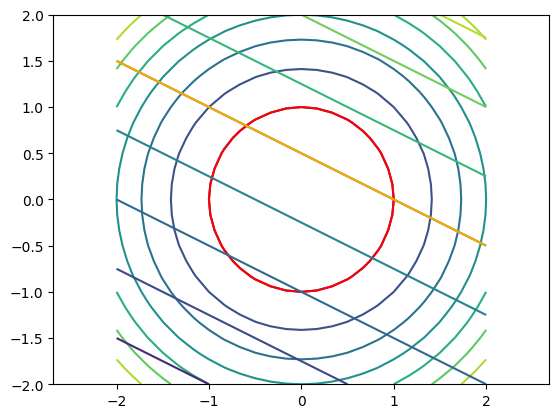

In [25]:
m = 25
x = np.linspace(-2, 2, m)
X, Y = np.meshgrid(x, x)
XY = np.array([X.ravel(),Y.ravel()])
Z = mpoly(XY, A)
Z = Z.reshape((2,m,m))
plt.contour(X, Y, Z[0]); plt.contour(X, Y, Z[0], levels=[0], colors='red')
plt.contour(X, Y, Z[1]); plt.contour(X, Y, Z[1], levels=[0], colors='orange')
plt.axis('equal')

In [26]:
def mnewton(f, J, x0, a, target=1e-6, maxstep=20):
    """Newton's method.
        f: the function to satisfy f(x)=0
        J; Jacobian df_i/dx_j
        x0: initial guess
        a: parameter for f(x,a), J(x,a)
        target: accuracy target"""
    n = len(x0)  # dimension
    x = np.zeros((maxstep+1, n))
    y = np.zeros((maxstep, n))
    x[0] = x0
    for i in range(maxstep):
        y[i] = f(x[i], a)
        if  sum(abs(y[i])) < target:
            break  # converged!
        x[i+1] = x[i] - np.linalg.inv(J(x[i], a))@y[i]
    else:
        print('did not coverge in', maxstep, 'steps.')
    return x[:i+1], y[:i+1]

In [27]:
x0 = [1,1]

In [28]:
xt, yt = mnewton(mpoly, dmpoly, x0, A)

(np.float64(-2.0), np.float64(2.0), np.float64(-2.0), np.float64(2.0))

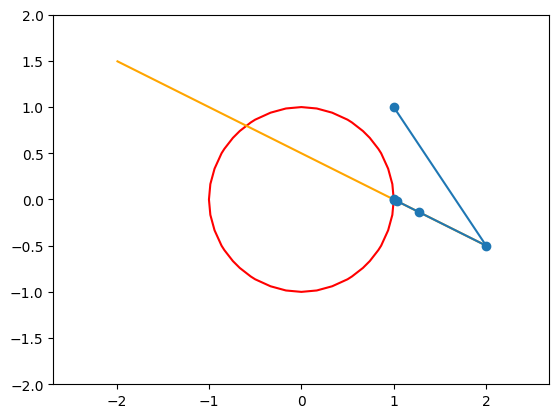

In [29]:
plt.contour(X, Y, Z[0], levels=[0], colors='red')
plt.contour(X, Y, Z[1], levels=[0], colors='orange')
plt.plot(xt[:,0], xt[:,1], 'o-')
plt.axis('equal')

## Quasi Newton method in n dimension
When the Jacobian is unknown or hard to compute, we can use quasi-Newton method in mulitple dimension space.

But to estimate a Jacobian, or slope, in $n$ dimension space, we need the output in $n+1$ points. There are several approximate methods to approximate the Jacobian. A one example is the *Broyden method*.

For the change of the input $\Delta \b{x}_k = \b{x}_{k} - \b{x}_{k-1}$ and
the corresponding change in the outpur $\Delta \b{f}_k = \b{f}(\b{x}_{k}) - \b{f}(\b{x}_{k-1})$,
the Jacobian is iteratively estimated as:

$$ J_{k+1} = J_k + \frac{(\Delta \b{f}_t - J_k \Delta \b{x}_k)\Delta \b{x}_k^T}
        {\Delta \b{x}_k^T \Delta \b{x}_k} $$
        
The corresponding inverse Jacobian is estimated without matrix inversion as:

$$ J^{-1}_{k+1} = J^{-1}_k + \frac{(\Delta \b{x}_k - J^{-1}_t\Delta \b{f}_k)\Delta \b{x}_k^T J^{-1}_k}
        {\Delta \b{x}_k^T J^{-1}_k \Delta \b{f}_k} $$

Then a new solution candidate is generated as

$$ \b{x}_{k+1} = \b{x}_k - J^{-1}_t \b{f}(\b{x}_k) $$

Broyden's and other methods for root finding of multdimensional functions are available in [scipy.optimize.root](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.root.html) library.

In [30]:
def broyden(f, x0, x1, a, target=1e-6, maxstep=20):
    """Broyden's method.
        f: the function to satisfy f(x)=0
        x0, x1: initial guess
        a: parameter for f(x,a)
        target: accuracy target"""
    n = len(x0)  # dimension
    x = np.zeros((maxstep+2, n))
    y = np.zeros((maxstep+1, n))
    x[0], x[1] = x0, x1
    y[0] = f(x[0], a)
    Ji = np.eye(n)  # Inverse Jacobian estimate
    for i in range(1,maxstep+1):
        y[i] = f(x[i], a)
        if  sum(abs(y[i])) < target:
            break  # converged!
        dx = x[i] - x[i-1]
        df = y[i] - y[i-1]
        #Ji = Ji + np.outer((dx - Ji@df),(dx - Ji@df).T)/((dx - Ji@df).T@df)  # SR1 method
        Ji = Ji + np.outer((dx - Ji@df),(dx.T@Ji))/(dx@Ji@df)
        #print(x[i], Ji)
        x[i+1] = x[i] - Ji@y[i]
    else:
        print('did not coverge in', maxstep, 'steps.')
    return x[:i+1], y[:i+1]

In [34]:
x0, x1 = [0,1], [1,1]
xt, yt = broyden(mpoly, x0, x1, A)
print(xt[-1], yt[-1])

[9.99999979e-01 3.20562066e-08] [-4.26952350e-08  4.27647949e-08]


In [32]:
x0, x1 = [-1,0], [-1,1]
xt, yt = broyden(mpoly, x0, x1, A)
print(xt[-1], yt[-1])

[-0.6000001   0.80000005] [2.07953035e-07 1.11022302e-16]


(np.float64(-2.0), np.float64(2.0), np.float64(-2.0), np.float64(2.0))

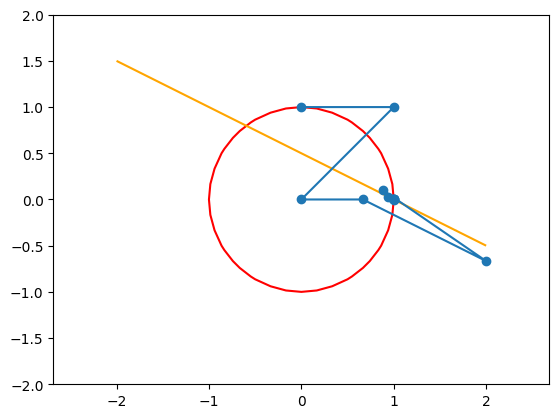

In [35]:
plt.contour(X, Y, Z[0], levels=[0], colors='red')
plt.contour(X, Y, Z[1], levels=[0], colors='orange')
plt.plot(xt[:,0], xt[:,1], 'o-')
plt.axis('equal')

## Discrete-time Dynamics
We have already seen the iterative dynamics by multiplication of a matrix, which can cause expansion, shrinkage, and rotation.  
With nonlinear mapping, more varieties of behaviors including chaos can be observed.

### 1D Dynamics
The simplest case is the logistic map.

$$ x_{k+1} = a x_k(1 - x_k) $$

In [36]:
def logistic(x, a):
    """logistic map: f(x) = a*x*(1-x)"""
    return a*x*(1 - x)

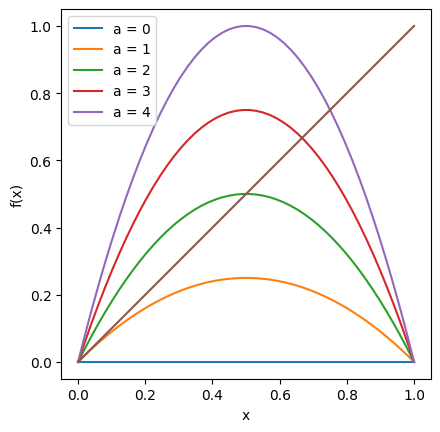

In [37]:
x = np.linspace(0, 1, 50)
# plot with different levels of a
A = np.arange(5)
leg = []
for a in A:
    y = logistic(x, a)
    plt.plot(x, y)
    leg.append('a = {}'.format(a))
plt.legend(leg)
plt.plot([0,1], [0,1])  # x=f(x) line
plt.xlabel('x'); plt.ylabel('f(x)')
plt.axis('square');

In [38]:
def iterate(f, x0, a, steps=100):
    """x0: initial value
        a: parameter to f(x,a)"""
    x = np.zeros(steps+1)
    x[0] = x0
    for k in range(steps):
        x[k+1] = f(x[k], a)
    return x

Try iteration with different parameter $a$.

array([0.00490035, 0.00487633, 0.00485256, 0.00482901, 0.00480569,
       0.00478259, 0.00475972, 0.00473707, 0.00471463, 0.0046924 ])

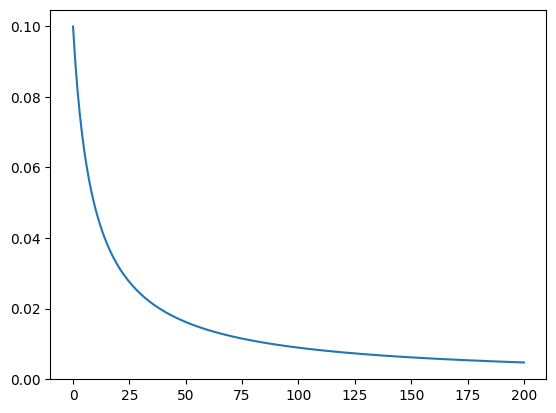

In [39]:
a = 1
xt = iterate(logistic, 0.1, a, 200)
plt.plot(xt)
xt[-10:] # last 10 points

array([0.68272042, 0.64983975, 0.68264415, 0.64992335, 0.68256897,
       0.65000571, 0.68249486, 0.65008688, 0.68242179, 0.65016688])

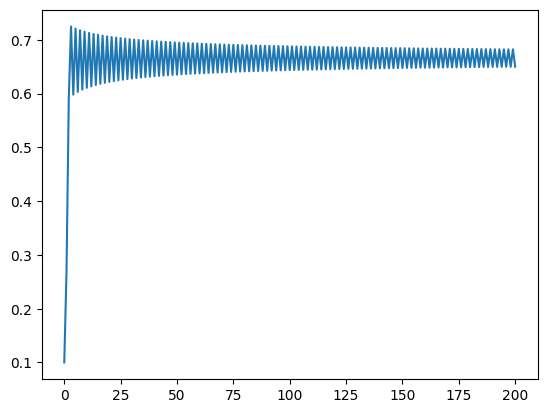

In [44]:
a = 3
xt = iterate(logistic, 0.1, a, 200)
plt.plot(xt)
xt[-10:] # last 10 points

array([0.38281968, 0.82694071, 0.50088421, 0.87499726, 0.38281968,
       0.82694071, 0.50088421, 0.87499726, 0.38281968, 0.82694071])

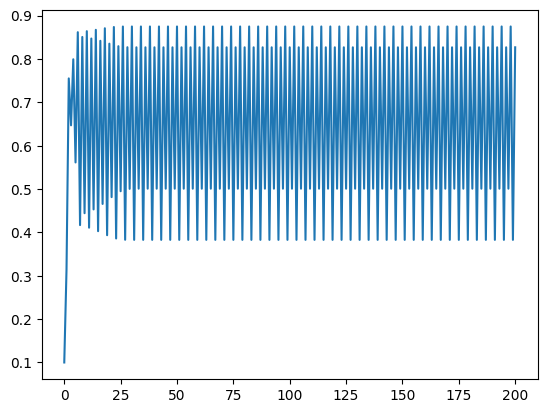

In [41]:
a = 3.5
xt = iterate(logistic, 0.1, a, 200)
plt.plot(xt)
xt[-10:] # last 10 points

Trajectory in $x_k$-$x_{k+1}$ plane, called "cobsplot".

In [42]:
def cobsplot(x):
    """cobsplot of trajectory x"""
    plt.plot([0,1], [0,1])  # x=f(x) line
    x2 = np.repeat(x, 2)  # duplicate items
    plt.plot(x2[:-1], x2[1:], lw=0.5) # (x0,x1), (x1,x1), (x1,x2),...
    plt.xlabel('$x_k$'); plt.ylabel('$x_{k+1}$');
    plt.axis('square');

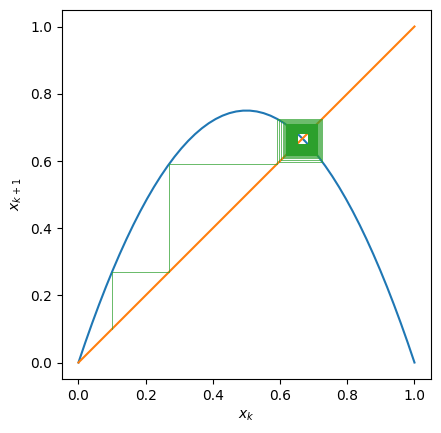

In [45]:
plt.plot(x, logistic(x, a))  # plot the map
cobsplot(xt)  # plot the trajectory

It is known that $3.57<a<4$ can cause chaotic oscillation.

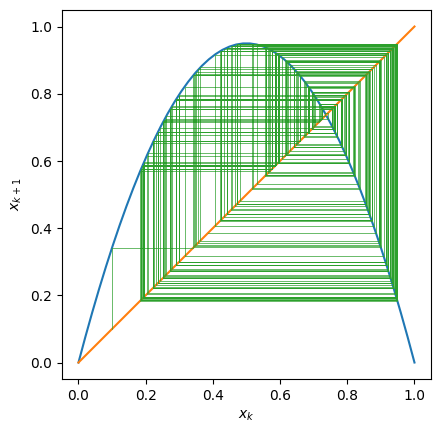

In [46]:
a = 3.8
xt = iterate(logistic, 0.1, a, 200)
plt.plot(x, logistic(x, a))  # plot the map
cobsplot(xt)  # plot the trajectory

### 2D Dynamics
Let us see an example of the Hénon map:

$$        x_{k+1} = 1 - a x_k^2 + y_k $$

$$ y_{k+1} = b x_k $$

In [47]:
def henon(xy, ab=[1.4, 0.3]):
    """Henon map: stretch and fold
        x_{k+1} = 1 - a*x_k**2 + y_k
        y_{k+1} = b*x_k
        xy: state [x, y]
        ab: parameters [a, b]
    """
    x = 1 - ab[0]*xy[0]**2 + xy[1]
    y = ab[1]*xy[0]
    return np.array([x, y])

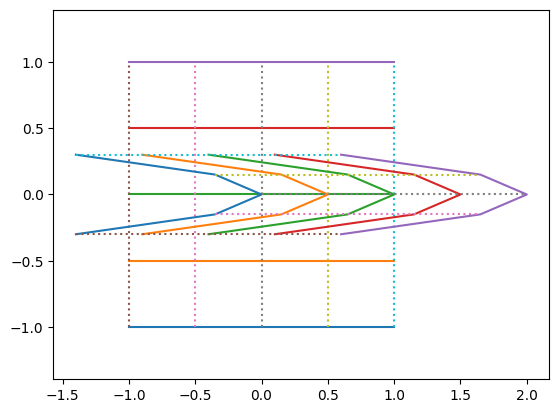

In [48]:
x = np.linspace(-1,1,5)
X, Y = np.meshgrid(x,x)
plt.plot(X.T,Y.T); plt.plot(X,Y,':'); # original gird
fXY = henon([X,Y])
plt.plot(fXY[0].T,fXY[1].T); plt.plot(fXY[0],fXY[1],':') # mapped grid
plt.axis('equal');

In [49]:
henon([1,1])

array([0.6, 0.3])

In [50]:
def iterate_vec(f, x0, *args, steps=100):
    """f: n-dimensional map
        x0: initial vector
        *args: optional parameter to f(x,*args) """
    n = len(x0)  # state dimension
    x = np.zeros((steps+1, n))
    x[0] = x0
    for k in range(steps):
        x[k+1] = f(x[k], *args)
    return x

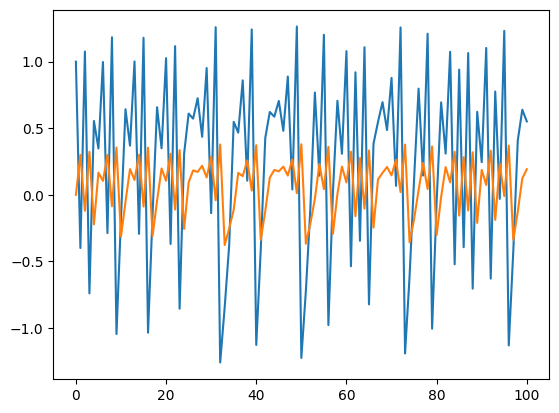

In [51]:
x = iterate_vec(henon, [1, 0])
plt.plot(x);

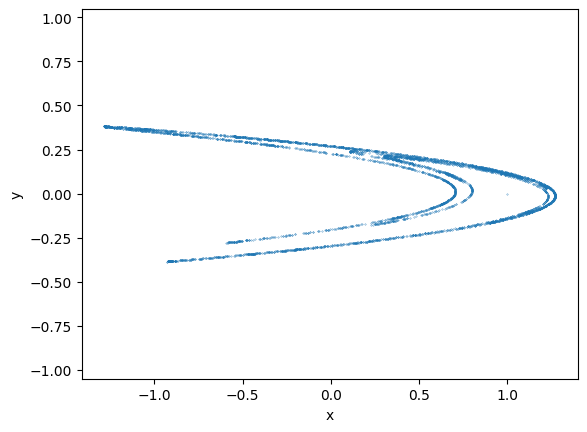

In [52]:
x = iterate_vec(henon, [1, 0], [1.4, 0.3], steps=5000)
plt.plot(x[:,0], x[:,1], '.', markersize=0.5)
plt.xlabel('x'); plt.ylabel('y'); plt.axis('equal');

Here's another example:  Gumowski-Mira map, which originates from a model of accelerator beams:

$$ x_{n+1} = y_n + \alpha y_n (1-\sigma y_n^2) + g(x_n) $$

$$ y_{n+1} = -x_n + g(x_{n+1}) $$

$$ g(x) = \mu x + \frac{2(1-\mu)x^2}{1+x^2} $$

In [53]:
def gumowski_mira(xy, asm=[0.009, 0.05, -0.801]):
    """Gumowski-Mira map:
        x_{k+1} = y_n + alpha y_n (1-sigma y_n^2) + g(x_n)
        y_{k+1} = -x_n + g(x_{n+1})
        g(x) = mu x + \frac{2(1-mu)x^2}{1+x^2}
        xy: state [x, y]
        asm: parameters [a, sigma, mu]
    """
    x, y = np.array(xy, dtype=float)  # unpack array
    alpha, sigma, mu = np.array(asm, dtype=float)
    # local function
    def g(x):
        return mu*x + 2*(1-mu)*x**2/(1+x**2)

    x1 = y + alpha*y*(1 - sigma*y**2) + g(x)
    y1 = -x + g(x1)
    return np.array([x1, y1])

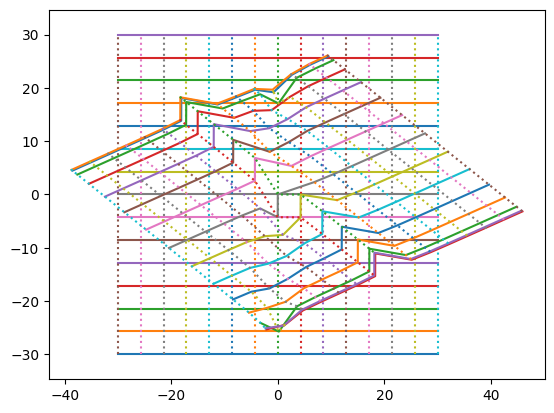

In [54]:
x = np.linspace(-30,30,15)
X, Y = np.meshgrid(x,x)
plt.plot(X.T,Y.T); plt.plot(X,Y,':'); # original gird
fXY = gumowski_mira([X,Y])
plt.plot(fXY[0].T,fXY[1].T); plt.plot(fXY[0],fXY[1],':') # mapped grid
plt.axis('equal');

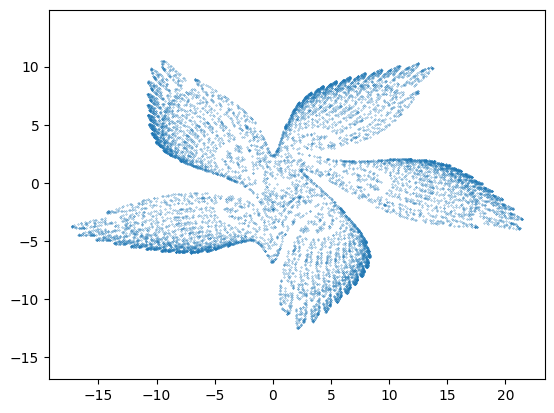

In [55]:
x = iterate_vec(gumowski_mira, [1, 1], steps=10000)
plt.plot(x[:,0], x[:,1], '.', markersize=0.5)
plt.axis('equal');

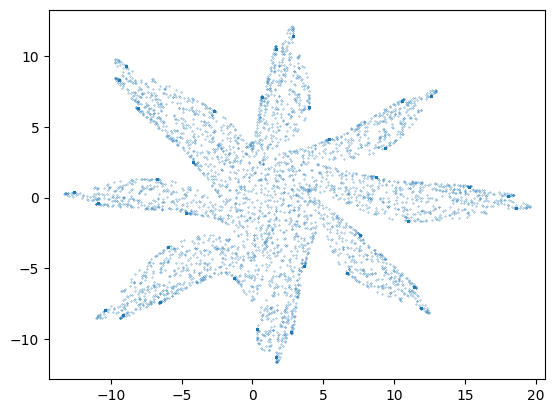

In [56]:
x = iterate_vec(gumowski_mira, [1, 1], [0.009, 0.05, -0.701], steps=10000)
plt.plot(x[:,0], x[:,1], '.', markersize=0.5)
plt.axis('equal');

## Recursive call
In Python and other modern languages, a function and call itself from inside. This can allow compact coding for complex functions.

In [57]:
def factorial(n):
    """factorial by recursice call"""
    if n == 0:
        return 1
    else:
        return factorial(n-1)*n

In [58]:
factorial(4)

24

### Drawing fractals
Recursive calls can be used for drawing *fractal* figures that have multi-scale self-similar structures.

One example is the *Cantor set*, which is made by iteratively removing the middle part of a segment.

In [59]:
def cantorplot(x0=0, x1=1, a=1/3, e=1e-4):
    """draw a Cantor set
    x0, x1: end points
    a: fraction to fill
    e: minimal resolution"""
    u = x1 - x0  # length
    if abs(u) < e:  # for a very short segment
        plt.plot([x0, x1], [0, 0])  # straight line
    else:
        cantorplot(x0, x0+a*u, a, e)  # left 1/3
        cantorplot(x1-a*u, x1, a, e)  # right 1/3

In [60]:
# Interactive mode to allow zooming in
%matplotlib widget

ValueError: Key backend: 'module://ipympl.backend_nbagg' is not a valid value for backend; supported values are ['gtk3agg', 'gtk3cairo', 'gtk4agg', 'gtk4cairo', 'macosx', 'nbagg', 'notebook', 'qtagg', 'qtcairo', 'qt5agg', 'qt5cairo', 'tkagg', 'tkcairo', 'webagg', 'wx', 'wxagg', 'wxcairo', 'agg', 'cairo', 'pdf', 'pgf', 'ps', 'svg', 'template', 'inline']

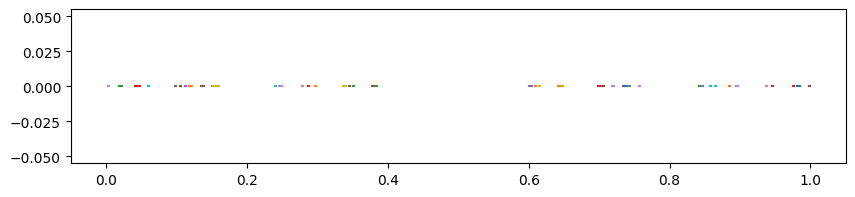

In [61]:
plt.figure(figsize=(10,2))
cantorplot(a=0.4)

Here is an example of drawing complex lines like a coastline or a clowd by replacing a segment with zig-zag segments.

In [62]:
def fractaline(x0=[0,0], x1=[1,0], a=[0, 0.3, 0], e=1e-2):
    """draw a fractal line
    x0, x1: start, end points
    a: shifts of via points
    e: minimal resolution"""
    n = np.size(a)   # number of via points
    x = np.zeros((n+2,2))
    x[0], x[-1] = x0, x1
    u = x[-1] - x[0]   # connecting vector
    v = np.array([-u[1],u[0]])  # orthogonal vector
    for i, ai in enumerate(a):
        x[i+1] = x0 + u*(i+1)/(n+1) + ai*v  # shift of via points
    #print(x)
    if sum((u**2)) < e**2: # if the segment is very short
        plt.plot(x[:,0],x[:,1])  # draw a straight line
    else:
        for i in range(n+1):  # n segments
            fractaline(x[i], x[i+1], a, e)
    plt.axis('equal');

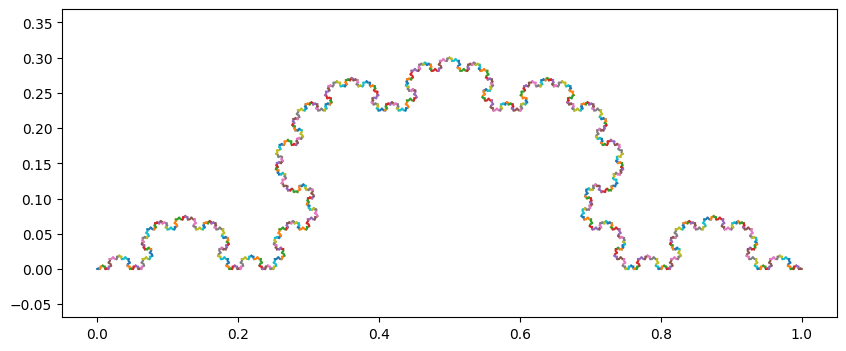

In [63]:
plt.figure(figsize=(10,4))
fractaline()

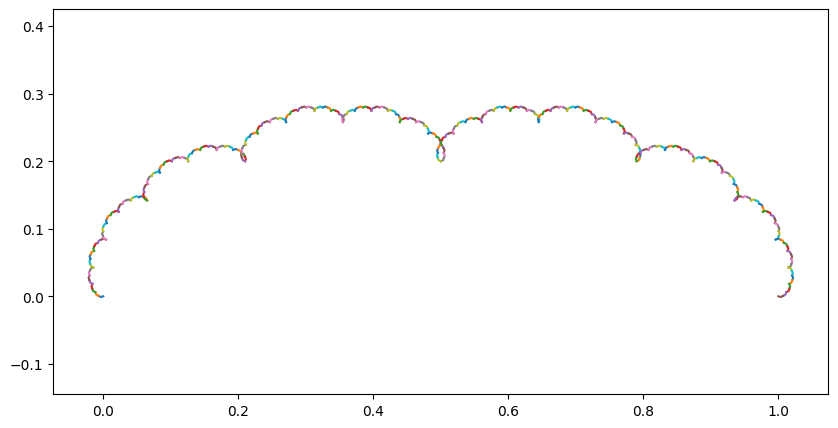

In [64]:
plt.figure(figsize=(10,5))
fractaline(a=[0.2])